# Dome: weekly expanding-window model and economic comparison

Initial training uses 28 calendar days. Models refit weekly using all earlier known labels; settings retune every four weeks using earlier chronological inner validation. Forward evaluation spans 11 November 2025?3 February 2026 at 08:00 UTC. N=3 is primary, N=5 secondary.

Opportunity prediction and economic evaluation remain separate. This retrospective development study uses both previously constructed Dome data segments; the original experiments remain preserved.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import torch
from IPython.display import display,Image
from threadpoolctl import threadpool_limits
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.common import sha256
from src.reporting.walk_forward import verify,verify_replay,LABELS
MODELS=ROOT/'results/walk_forward'
REPLAY=ROOT/'results/walk_forward_replay'
DATA=ROOT/'data/processed/walk_forward_v1'
torch.set_num_threads(4)
with threadpool_limits(limits=4):
    display(verify(MODELS,DATA))
verify_replay(REPLAY)
manifest=json.loads((MODELS/'analysis/manifest.json').read_text())
assert manifest['models_completion_sha256']==sha256(MODELS/'complete.json')
assert manifest['replay_completion_sha256']==sha256(REPLAY/'complete.json')
assert manifest['reporter_sha256']==sha256(ROOT/'src/reporting/walk_forward.py')
for name,digest in manifest['files_sha256'].items():
    assert sha256(MODELS/'analysis'/name)==digest,name
display(json.loads((MODELS/'analysis/population.json').read_text()))
display(pd.read_csv(MODELS/'populations.csv'))

{'weekly_fits_checked': 199, 'scores_reproduced': False, 'folds': 13}

{'scheduled_hours': 2024,
 'event_hours': 19766,
 'events': 44,
 'known': 15787,
 'positive': 359,
 'unknown': 3979,
 'positive_events': 12,
 'competitive_hours_n3': 1887,
 'median_candidates': 9.0,
 'maximum_candidates': 19,
 'total_peak_value': 8838.30666999995}

,origin,start,end,training_rows,training_positive,training_events,training_last,evaluation_rows,evaluation_known,evaluation_positive,evaluation_events,scheduled_hours
0,week_00,2025-11-11 00:00:00+00:00,2025-11-18 00:00:00+00:00,7652,110,25,2025-11-10 22:00:00+00:00,2861,2263,72,20,168
1,week_01,2025-11-18 00:00:00+00:00,2025-11-25 00:00:00+00:00,9915,182,27,2025-11-17 22:00:00+00:00,2914,2274,102,20,168
2,week_02,2025-11-25 00:00:00+00:00,2025-12-02 00:00:00+00:00,12188,284,31,2025-11-24 22:00:00+00:00,2947,2118,53,20,168
3,week_03,2025-12-02 00:00:00+00:00,2025-12-09 00:00:00+00:00,14309,338,33,2025-12-01 22:00:00+00:00,2460,1934,55,19,168
4,week_04,2025-12-09 00:00:00+00:00,2025-12-16 00:00:00+00:00,16244,393,37,2025-12-08 22:00:00+00:00,2020,1720,16,17,168
5,week_05,2025-12-16 00:00:00+00:00,2025-12-23 00:00:00+00:00,17963,409,42,2025-12-15 22:00:00+00:00,1812,1732,41,13,168
6,week_06,2025-12-23 00:00:00+00:00,2025-12-30 00:00:00+00:00,19696,450,44,2025-12-22 22:00:00+00:00,1300,1182,3,11,168
7,week_07,2025-12-30 00:00:00+00:00,2026-01-06 00:00:00+00:00,20883,453,45,2025-12-29 22:00:00+00:00,746,714,1,8,168
8,week_08,2026-01-06 00:00:00+00:00,2026-01-13 00:00:00+00:00,21598,454,47,2026-01-05 22:00:00+00:00,763,711,4,6,168
9,week_09,2026-01-13 00:00:00+00:00,2026-01-20 00:00:00+00:00,22308,458,49,2026-01-12 22:00:00+00:00,693,654,12,6,168


## Reproduce optionally

Default execution verifies and displays saved artifacts without fitting or downloading. Set `RUN_STUDY=True` to build a separate dataset view, fit the models, run economic replay and generate analysis in fresh directories. Earlier study files are not replaced. GPU is used if available; CPU is supported. Reproduction can take substantial time. Checkpointed model/replay runs resume only with the same recorded code and input hashes.

In [2]:
RUN_STUDY=False
if RUN_STUDY:
    from src.data.walk_forward import build
    from src.models.walk_forward import run as train
    from src.simulator.walk_forward import run as replay
    from src.reporting.walk_forward import analyze
    data=ROOT/'data/processed/walk_forward_reproduction'
    models=ROOT/'results/runs/walk_forward_reproduction'
    economic=ROOT/'results/runs/walk_forward_replay_reproduction'
    build(data)
    with threadpool_limits(limits=4):
        train(models,data,'cuda' if torch.cuda.is_available() else 'cpu')
        replay(economic,models)
        analyze(models,economic,data)

## Prediction and model selection

The primary criterion is peak quoted-value capture@3; positive-hour recall and average precision break ties. These values describe recorded opportunity magnitude, not realized or simulated trading profits. Every eligible event competes before its outcome is consulted. Unknown outcomes consume slots and remain missing.

Fixed book-only/combined controls isolate adding metadata with unchanged model settings. Tuned classical models and both two-stage models use combined features. Ensembles have fixed equal rank weights. Both inner tuning and preprocessing use earlier observations only.

,model,top_n,positive_windows,captured_positive_windows,recall,peak_value_recall,selected_unknown_fraction,average_precision
96,fixed_book_random_forest,3,359,340,0.947075,0.995271,0.161560,0.524823
192,fixed_combined_random_forest,3,359,333,0.927577,0.994094,0.195881,0.505041
160,fixed_combined_logistic,3,359,331,0.922006,0.991950,0.116022,0.547769
0,classifier_rank_ensemble,3,359,334,0.930362,0.991558,0.173447,0.131175
416,tuned_combined_logistic,3,359,334,0.930362,0.990640,0.114180,0.529984
384,tabm_two_stage,3,359,316,0.880223,0.990429,0.103633,0.373549
64,fixed_book_logistic,3,359,329,0.916435,0.988062,0.117529,0.533304
224,fixed_combined_xgboost,3,359,321,0.894150,0.987453,0.213461,0.551591
512,value_rank_ensemble,3,359,315,0.877437,0.985846,0.127909,0.110161
256,forest_two_stage,3,359,315,0.877437,0.985745,0.212289,0.298414


,model,top_n,positive_windows,captured_positive_windows,recall,peak_value_recall,selected_unknown_fraction,average_precision
161,fixed_combined_logistic,5,359,357,0.994429,0.999997,0.120017,0.547769
97,fixed_book_random_forest,5,359,352,0.980501,0.999920,0.185667,0.524823
449,tuned_combined_random_forest,5,359,352,0.980501,0.999824,0.200494,0.527037
65,fixed_book_logistic,5,359,354,0.986072,0.999756,0.121736,0.533304
193,fixed_combined_random_forest,5,359,351,0.977716,0.999499,0.197271,0.505041
225,fixed_combined_xgboost,5,359,350,0.974930,0.999483,0.202213,0.551591
481,tuned_combined_xgboost,5,359,349,0.972145,0.999328,0.201354,0.551950
129,fixed_book_xgboost,5,359,350,0.974930,0.998583,0.192543,0.547218
289,freshness_rule,5,359,323,0.899721,0.995293,0.100892,0.082621
417,tuned_combined_logistic,5,359,354,0.986072,0.993012,0.123885,0.529984


{'policy': 'fixed_book_random_forest',
 'objective': 'Pooled peak quoted-value capture@3, ties positive-hour capture then AP.',
 'selection_basis': 'Retrospective comparison of saved chronological predictions; no PnL-based fitting or tuning.',
 'latest_bundle': 'results\\walk_forward\\folds\\week_12\\bundle.json',
 'latest_bundle_sha256': '75b263eed136dbd9d0dc23644f6b3be8be1491142213c200031e061e91c0cdc1',
 'fitted_before': '2026-02-03 00:00:00+00:00',
 'inference': 'src.models.walk_forward.score_saved(folder,bundle,as_of_features)[policy]'}

,method,book_recall,combined_recall,recall_change,book_value_capture,combined_value_capture,value_change
0,logistic,0.916435,0.922006,0.005571,0.988062,0.991950,0.003888
1,random_forest,0.947075,0.927577,-0.019499,0.995271,0.994094,-0.001176
2,xgboost,0.899721,0.894150,-0.005571,0.829814,0.987453,0.157639


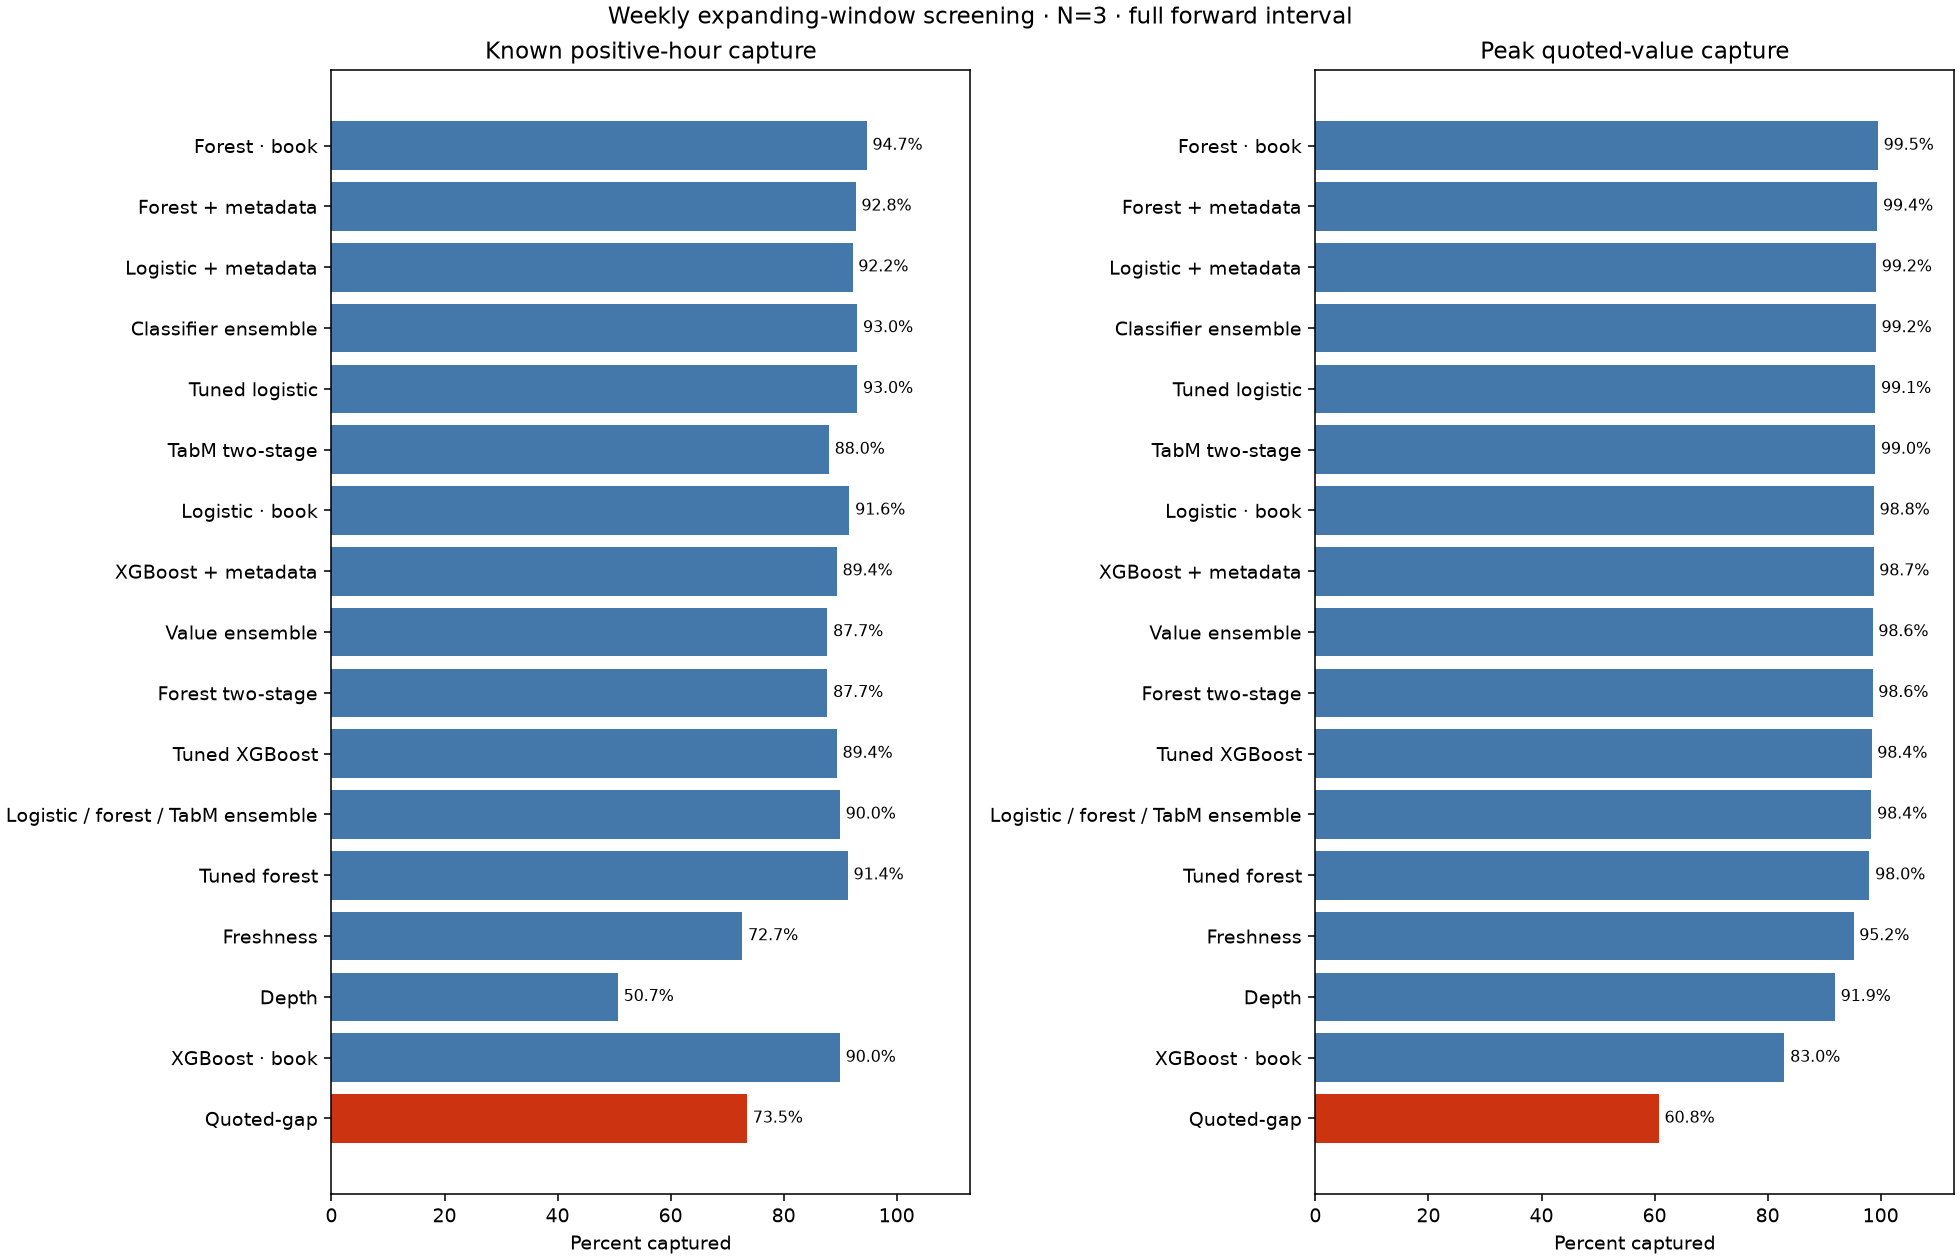

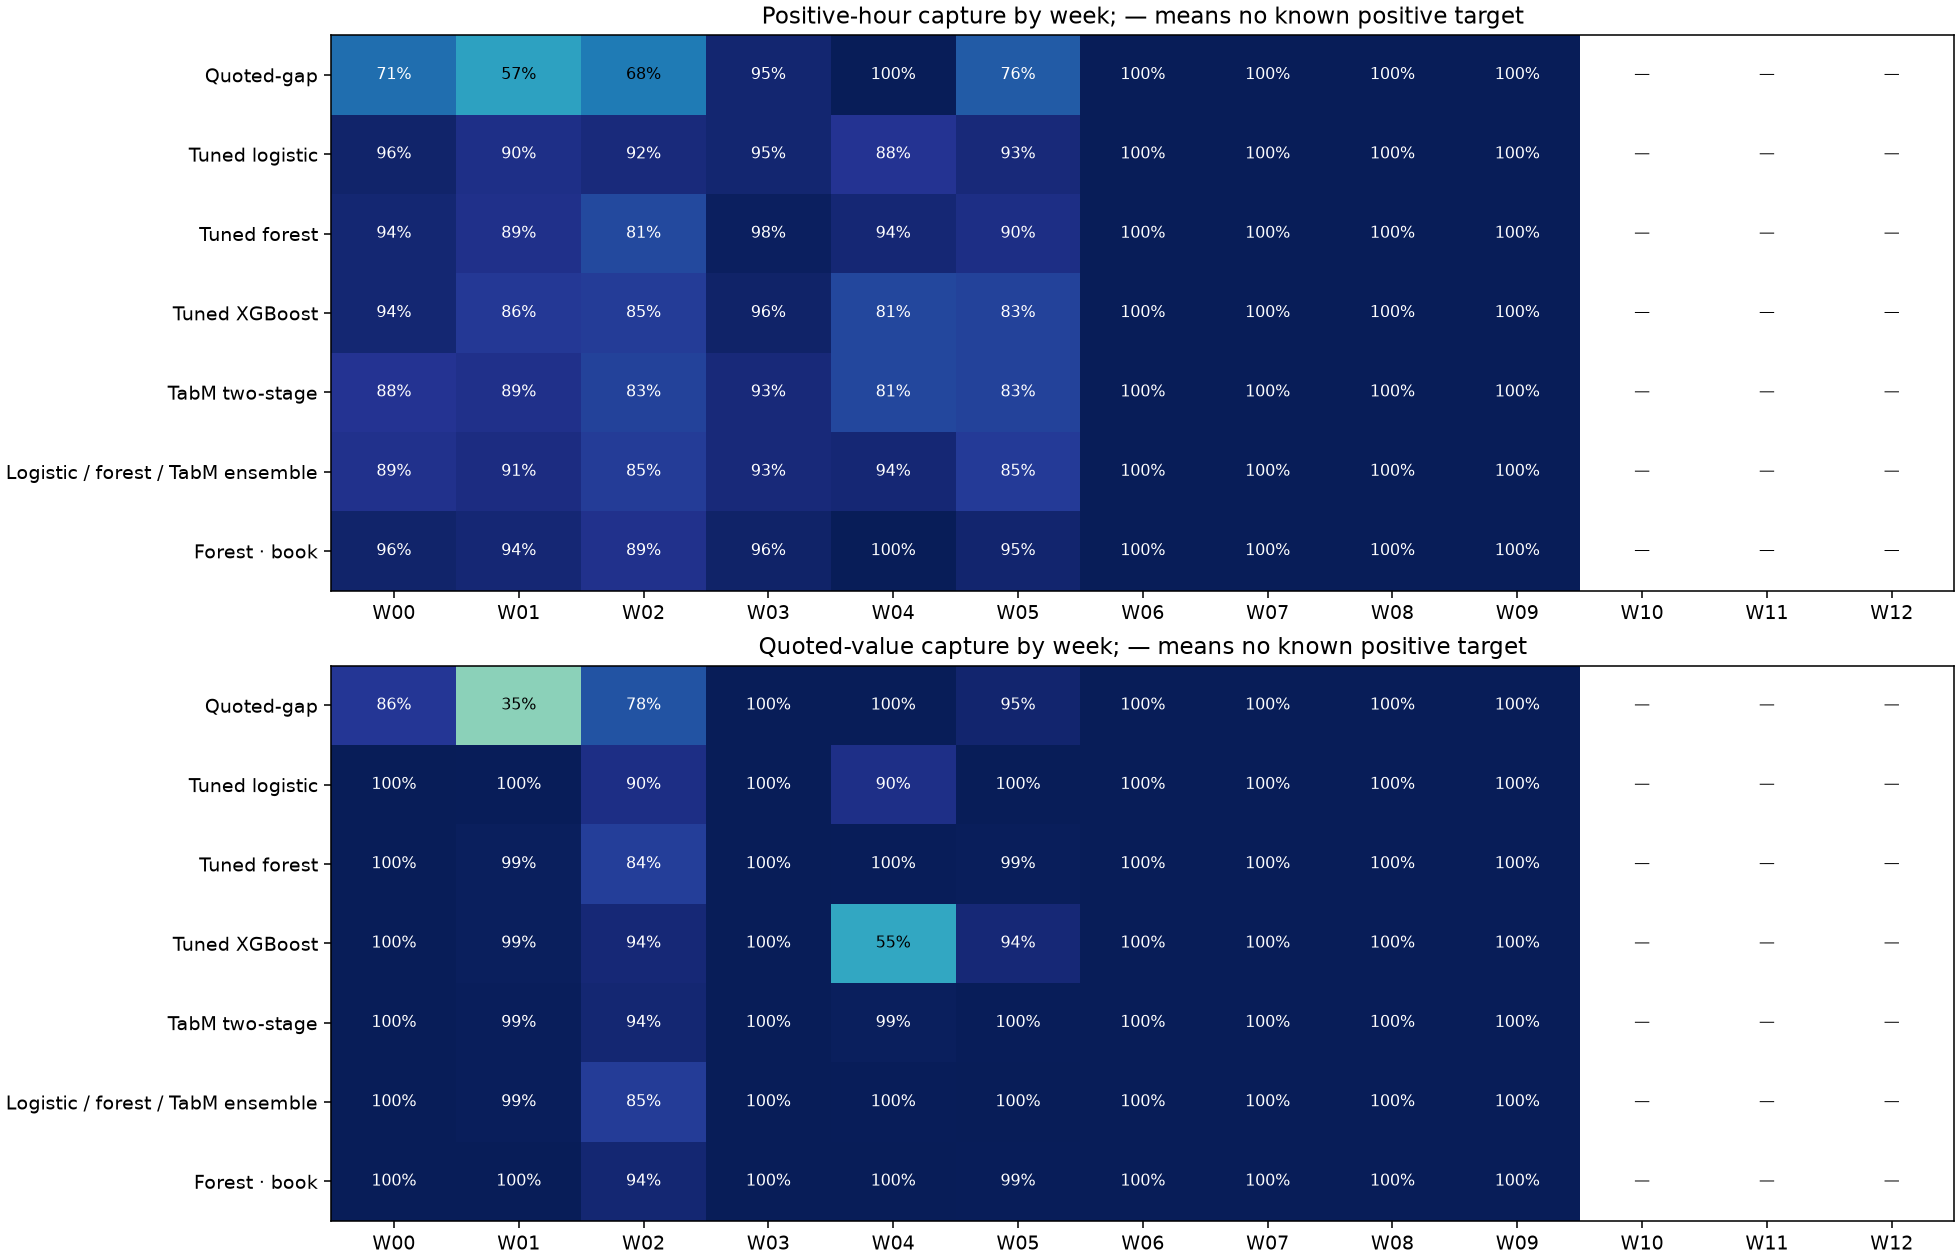

In [3]:
metrics=pd.read_csv(MODELS/'metrics.csv')
for n in (3,5):
    display(metrics.loc[metrics.scope.eq('all_events')&metrics.fold.eq('all')&metrics.top_n.eq(n),
        ['model','top_n','positive_windows','captured_positive_windows','recall','peak_value_recall','selected_unknown_fraction','average_precision']]
        .sort_values(['peak_value_recall','recall'],ascending=False))
display(json.loads((MODELS/'analysis/research_selection.json').read_text()))
display(pd.read_csv(MODELS/'analysis/metadata_comparison.csv'))
display(Image(filename=str(MODELS/'analysis/primary_capture.png')))
display(Image(filename=str(MODELS/'analysis/weekly_capture.png')))

## Economic evaluation

Primary execution assumes 100 ms total update-to-order-arrival delay, uncapped capital/shares, available-depth sizing and frozen decision-time limits. Per-leg fills depend on displayed support. Partial baskets unwind after one second. Zero exchange fees and zero additional attempt costs retain the frozen cohort scenario; there is no imposed failure probability, quote-age cutoff or persistence requirement.

Each policy/scenario retains one continuous event-level liquidity ledger across all weekly refits and the original January boundary. Unknown execution outcomes are counted and excluded from known P&L. Deterministic policies have 0/50/100/250/500 ms sensitivities; the 20 random policies and December-Fed exclusion run at 100 ms. No P&L is used for fitting or tuning.

,model,recall,peak_value_recall,known_pnl_usd,attempts,completed,unknown_attempts,max_drawdown_usd
0,fixed_book_random_forest,0.947075,0.995271,5873.31925,453,436,0,206.15062
1,fixed_combined_random_forest,0.927577,0.994094,5873.60247,456,439,0,206.15062
2,fixed_combined_logistic,0.922006,0.991950,5892.81347,434,416,0,206.19862
3,classifier_rank_ensemble,0.930362,0.991558,5902.49610,462,445,0,205.91262
4,tuned_combined_logistic,0.930362,0.990640,5896.85010,444,426,0,206.19862
5,tabm_two_stage,0.880223,0.990429,5857.98810,431,413,0,206.15062
6,fixed_book_logistic,0.916435,0.988062,5878.46544,438,420,0,206.19862
7,fixed_combined_xgboost,0.894150,0.987453,5915.38270,449,433,0,205.96062
8,value_rank_ensemble,0.877437,0.985846,5834.00944,428,410,0,206.15062
9,forest_two_stage,0.877437,0.985745,5921.18455,454,439,0,206.15062


{'seeds': 20,
 'mean': 1123.1505274999934,
 'minimum': 472.6088399999908,
 'maximum': 1963.2009299999927,
 'std': 367.9888394857317}

,model,scenario,arrival_delay_s,unwind_delay_s,attempts,completed,partial_attempts,unknown_attempts,completed_profit_usd,partial_pnl_usd,...,scope,top_n,fold,monitored_event_windows,selected_unknown_windows,selected_known_positive_windows,positive_hours_with_attempts,completion_rate,peak_inflight_reservations_usd,no_settlement_funding_usd
800,monitor_all,arrival_100ms,0.1,1.0,499,481,18,0,6361.98998,-417.02187,...,all_events,3,all,19766,3979,359,273,0.963928,72920.866,1.462161e+06


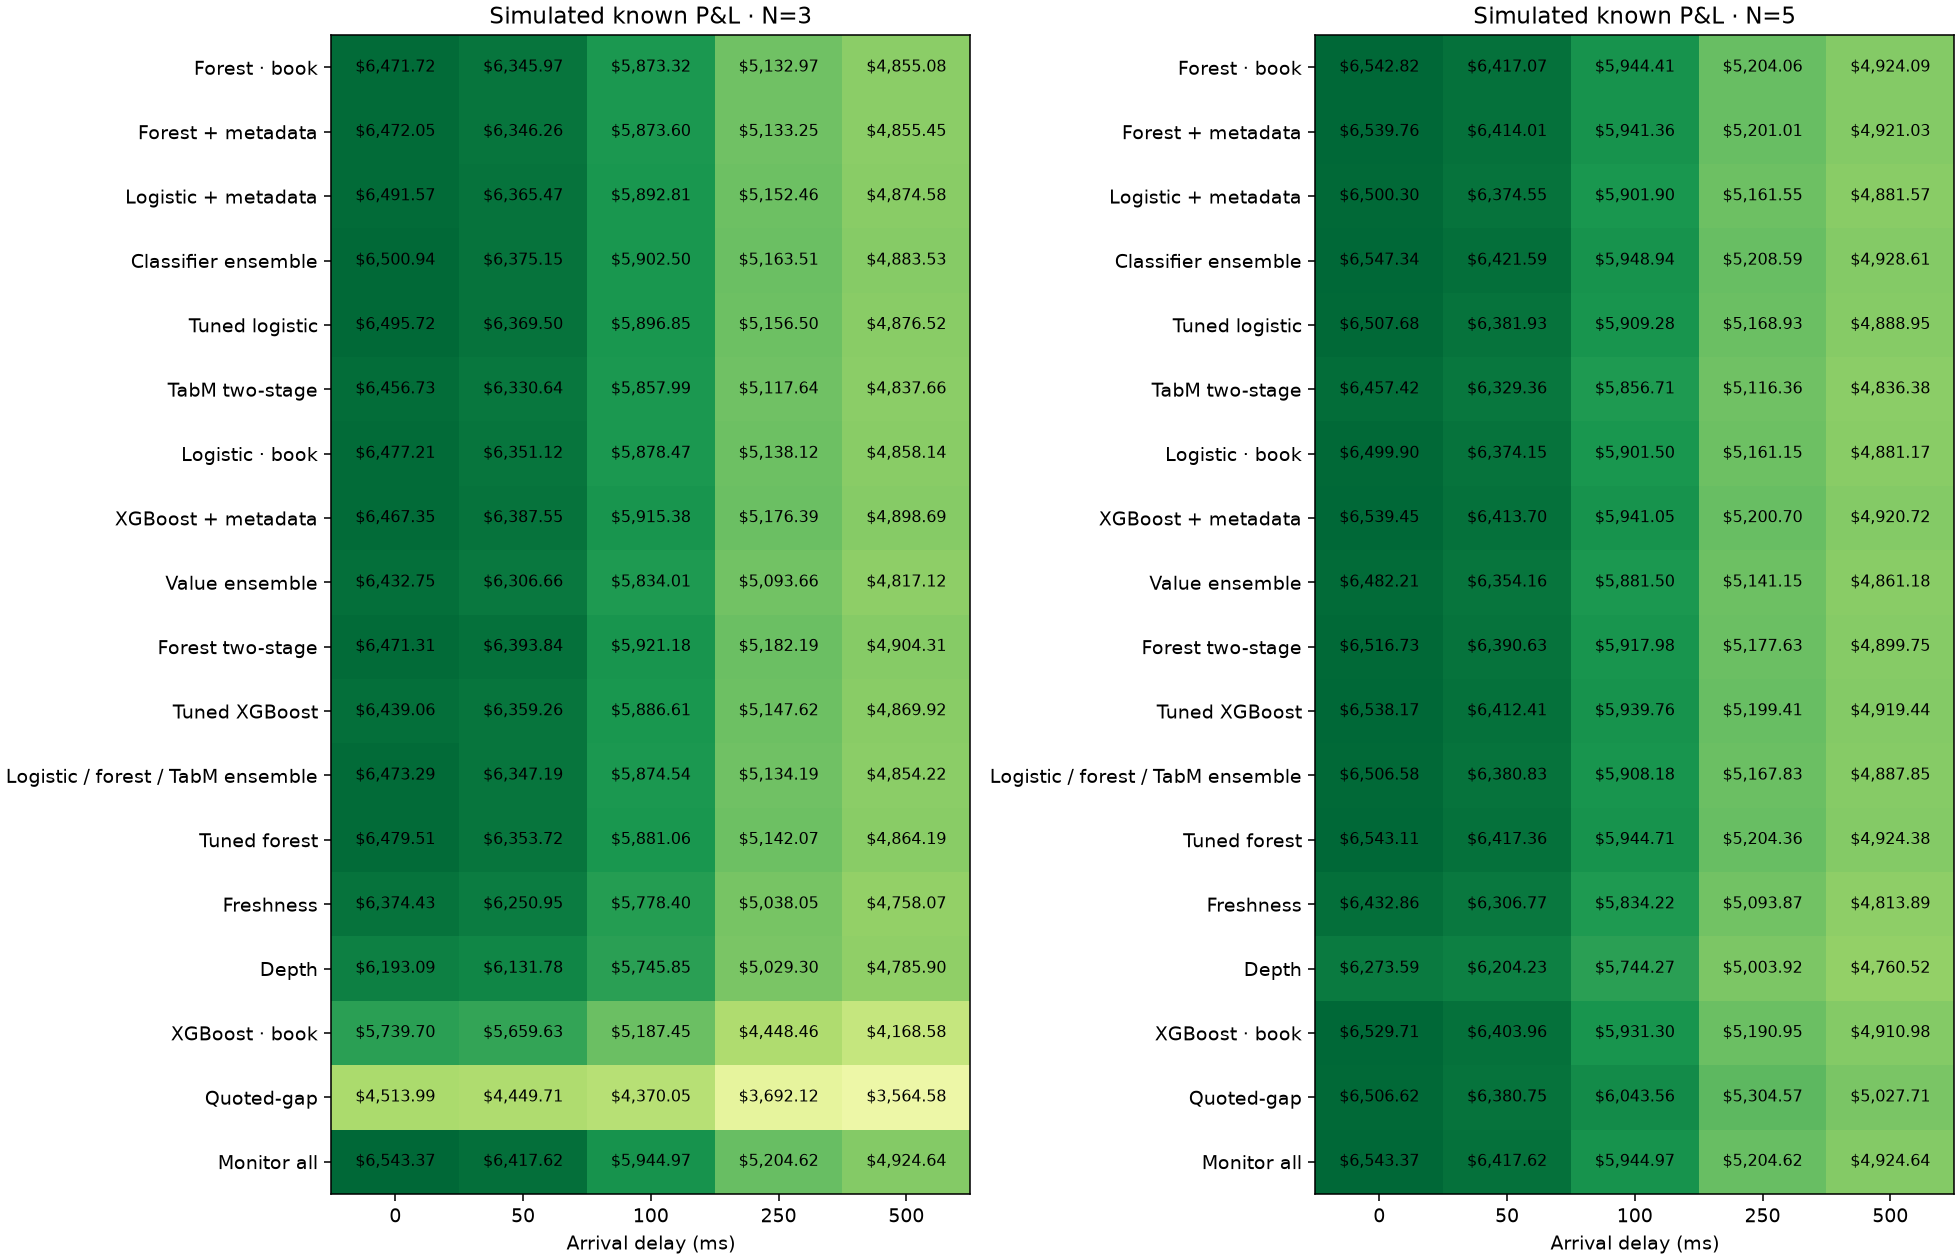

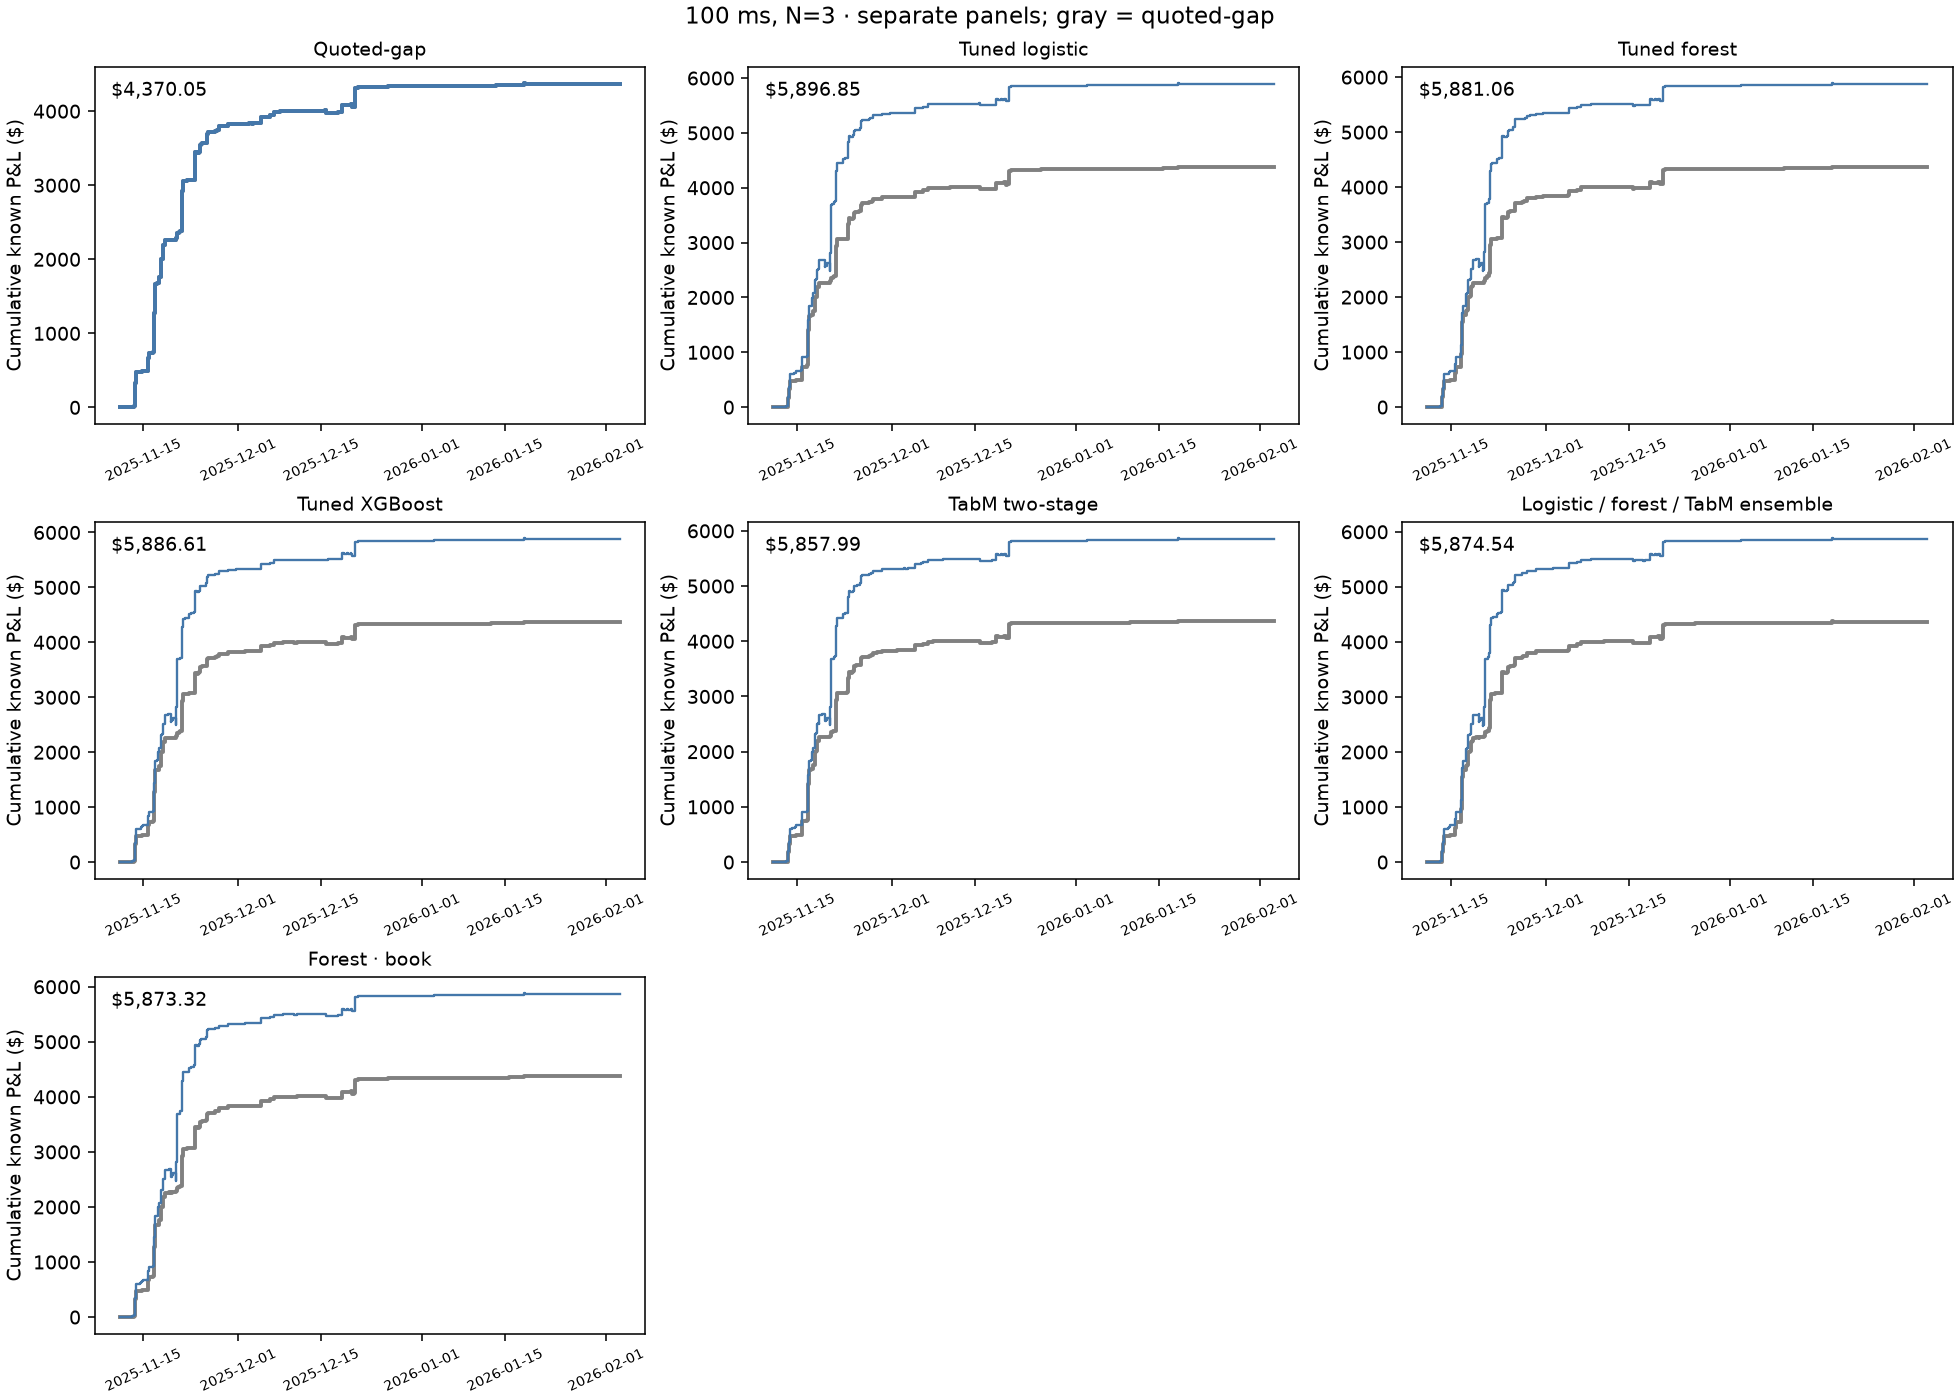

In [4]:
display(pd.read_csv(MODELS/'analysis/prediction_and_economics.csv')
    [['model','recall','peak_value_recall','known_pnl_usd','attempts','completed','unknown_attempts','max_drawdown_usd']])
display(json.loads((MODELS/'analysis/random_economics.json').read_text()))
economics=pd.read_csv(REPLAY/'summary.csv')
display(economics.loc[economics.scope.eq('all_events')&economics.fold.eq('all')&economics.top_n.eq(3)&economics.arrival_delay_s.eq(.1)&economics.model.eq('monitor_all')])
display(Image(filename=str(MODELS/'analysis/latency_economics.png')))
display(Image(filename=str(MODELS/'analysis/pnl_small_multiples.png')))

## Stability, concentration and segments

Pooled results can be dominated by a few events or weeks. The earlier/later segment breakdown also matters because the later candidate pool is much smaller. The December-Fed exclusion removes the event and reranks the remaining pool; its economics retain the same persistent replay rules.

Paired seven-day intervals condition on fixed fitted policies and this cohort. There are only 13 blocks, with a short last block, and no adjustment for multiple comparisons. They do not capture refitting or missing-outcome uncertainty. Weeks with no positives have undefined recall rather than zero performance.

In [5]:
display(metrics.loc[metrics.scope.eq('all_events')&metrics.fold.isin(['earlier_segment','later_segment'])&metrics.top_n.eq(3),
    ['fold','model','positive_windows','recall','peak_value_recall','competitive_windows']])
display(metrics.loc[metrics.scope.eq('exclude_december_fed')&metrics.fold.eq('all')&metrics.top_n.eq(3),
    ['model','positive_windows','recall','peak_value_recall']])
display(pd.read_csv(MODELS/'analysis/paired_capture_intervals.csv'))
display(pd.read_csv(MODELS/'analysis/paired_pnl_intervals.csv'))
contributions=pd.read_csv(MODELS/'analysis/event_capture.csv')
display(contributions.loc[contributions.model.eq('quoted_gap_rule')].sort_values('peak_value',ascending=False).head(12))
display(economics.loc[economics.scope.eq('exclude_december_fed')&economics.fold.eq('all')&~economics.model.str.startswith('random_'),
    ['model','known_pnl_usd','attempts','unknown_attempts']])
display(json.loads((MODELS/'analysis/verification.json').read_text()))

,fold,model,positive_windows,recall,peak_value_recall,competitive_windows
2,earlier_segment,classifier_rank_ensemble,343,0.927114,0.991476,1384
4,later_segment,classifier_rank_ensemble,16,1.000000,1.000000,503
34,earlier_segment,depth_rule,343,0.492711,0.918464,1384
36,later_segment,depth_rule,16,0.812500,0.996220,503
66,earlier_segment,fixed_book_logistic,343,0.912536,0.987947,1384
68,later_segment,fixed_book_logistic,16,1.000000,1.000000,503
98,earlier_segment,fixed_book_random_forest,343,0.944606,0.995225,1384
100,later_segment,fixed_book_random_forest,16,1.000000,1.000000,503
130,earlier_segment,fixed_book_xgboost,343,0.895044,0.828169,1384
132,later_segment,fixed_book_xgboost,16,1.000000,1.000000,503


,model,positive_windows,recall,peak_value_recall
544,classifier_rank_ensemble,263,0.923954,0.952975
576,depth_rule,263,0.349810,0.523423
608,fixed_book_logistic,263,0.946768,0.997215
640,fixed_book_random_forest,263,0.954373,0.975010
672,fixed_book_xgboost,263,0.920152,0.976936
704,fixed_combined_logistic,263,0.935361,0.996722
736,fixed_combined_random_forest,263,0.935361,0.972125
768,fixed_combined_xgboost,263,0.908745,0.973631
800,forest_two_stage,263,0.882129,0.925589
832,freshness_rule,263,0.749049,0.899546


,model,seven_day_blocks,recall_difference,recall_lower95,recall_upper95,recall_defined_draws,value_capture_difference,value_capture_lower95,value_capture_upper95,value_capture_defined_draws
0,classifier_rank_ensemble,13,0.194986,0.038959,0.286885,10000,0.383979,0.019054,0.598275,10000
1,depth_rule,13,-0.228412,-0.439796,-0.108107,10000,0.311630,-0.302141,0.555528,10000
2,fixed_book_logistic,13,0.181058,0.039383,0.265310,10000,0.380483,0.024064,0.597796,10000
3,fixed_book_random_forest,13,0.211699,0.071036,0.302961,10000,0.387692,0.023267,0.600594,10000
4,fixed_book_xgboost,13,0.164345,0.044301,0.226054,10000,0.222235,0.015773,0.308458,10000
5,fixed_combined_logistic,13,0.186630,0.016391,0.282724,10000,0.384371,0.021312,0.598995,10000
6,fixed_combined_random_forest,13,0.192201,0.050208,0.287569,10000,0.386515,0.022069,0.599997,10000
7,fixed_combined_xgboost,13,0.158774,0.034327,0.227361,10000,0.379874,0.009115,0.593469,10000
8,forest_two_stage,13,0.142061,0.016446,0.207695,10000,0.378166,0.014028,0.588352,10000
9,freshness_rule,13,-0.008357,-0.174178,0.097266,10000,0.344508,-0.115935,0.576088,10000


,model,difference_usd,lower95,upper95,blocks
0,fixed_book_random_forest,1503.26886,7.929840,3866.592860,13
1,fixed_combined_random_forest,1503.55208,7.185840,3879.322510,13
2,fixed_combined_logistic,1522.76308,4.637300,3902.704910,13
3,classifier_rank_ensemble,1532.44571,5.491300,3917.090080,13
4,tuned_combined_logistic,1526.79971,5.029300,3907.427080,13
5,tabm_two_stage,1487.93771,7.046620,3796.069959,13
6,fixed_book_logistic,1508.41505,4.935840,3872.434560,13
7,fixed_combined_xgboost,1545.33231,33.822270,3961.369621,13
8,value_rank_ensemble,1463.95905,5.314620,3755.256499,13
9,forest_two_stage,1551.13416,39.129600,3982.656858,13


,model,event_slug,positive,captured,peak_value,captured_value
463,quoted_gap_rule,fed-decision-in-december,96,59,7349.36237,4065.66206
464,quoted_gap_rule,fed-decision-in-january,148,125,911.71288,879.56864
467,quoted_gap_rule,honduras-presidential-election,38,21,457.66625,327.39014
442,quoted_gap_rule,avatar-fire-and-ash-opening-weekend-box-office,34,23,56.22870,39.16605
443,quoted_gap_rule,boxing-jake-paul-vs-anthony-joshua-third-optio...,9,9,36.51982,36.51982
468,quoted_gap_rule,largest-company-end-of-november,6,5,12.91743,10.82211
482,quoted_gap_rule,which-party-holds-the-most-seats-after-argenti...,3,1,7.63683,5.45702
481,quoted_gap_rule,which-company-has-the-best-ai-model-end-of-jan...,8,6,3.42800,2.63600
466,quoted_gap_rule,gensyn-public-sale-total-commitments,7,7,2.23300,2.23300
470,quoted_gap_rule,next-country-us-strikes-918,3,3,0.31986,0.31986


,model,known_pnl_usd,attempts,unknown_attempts
3520,classifier_rank_ensemble,731.94676,276,0
3536,depth_rule,555.52738,94,0
3552,fixed_book_logistic,697.08369,245,0
3568,fixed_book_random_forest,730.52105,283,0
3584,fixed_book_xgboost,771.20141,271,0
3600,fixed_combined_logistic,696.05723,238,0
3616,fixed_combined_random_forest,727.34044,281,0
3632,fixed_combined_xgboost,771.14521,270,0
3648,forest_two_stage,756.47500,270,0
3664,freshness_rule,630.50467,212,0


{'weekly_fits_checked': 199,
 'scores_reproduced': True,
 'folds': 13,
 'original_files_checked': 2913,
 'original_files_unchanged': True,
 'economic_replay_verified': True}

The [research report](../docs/reports/dome_walk_forward.md) gives the full methods, results, scope and reproduction commands. `analysis/research_selection.json` identifies the retrospectively selected opportunity policy and latest saved weekly bundle. The inference helper scores supplied as-of features only; the caller must construct those features and the eligible event pool consistently.